In [ ]:
import gzip
import shutil
import os

# Name of input output files
input_file = "fafb_v783_princeton_synapse_table.csv.gz"
output_file = "fafb_v783_princeton_synapse_table.csv"

if not os.path.exists(input_file):
    print(f"Error: File {input_file} was not found in folder!")
else:
    print("Starting de-archivisation... It can take few minutes.")
    try:
        with gzip.open(input_file, 'rb') as f_in:
            with open(output_file, 'wb') as f_out:
                # Copy data partialy, for not making operative memory full
                shutil.copyfileobj(f_in, f_out)
        print(f"Success! File {output_file} is ready.")
    except Exception as e:
        print(f"Error during re-archivisation: {e}")
        print("Possible, File was downloaded with Error. Please downloaded it again.")

Starting de-archivisation... It can take few minutes.
Success! File fafb_v783_princeton_synapse_table.csv is ready.


In [9]:
import dask.dataframe as dd

print("Reading CSV... (it can take 5-10 minutes)")
# Use accurate name of file
ddf = dd.read_csv(
    "fafb_v783_princeton_synapse_table.csv",
    dtype={
        'pre': 'int64', 'post': 'int64',
        'pre_x': 'float32', 'pre_y': 'float32', 'pre_z': 'float32'
    }
)

print("Save in Parquet... (it takes time)")
ddf.to_parquet("fafb_synapses.parquet", engine='pyarrow')
print("Complete! Now you can download it through pd.read_parquet()")

Reading CSV... (it can take 5-10 minutes)
Save in Parquet... (it takes time)
Complete! Now you can download it through pd.read_parquet()


In [ ]:
import os
print("Current folder:", os.getcwd())
print("Files in folder:", [f for f in os.listdir() if "fafb" in f])

Current package: c:\Users\mimal\Documents\CODE\Non published
Files in package: ['fafb_synapses.parquet', 'fafb_v783_princeton_synapse_table.csv', 'fafb_v783_princeton_synapse_table.csv.gz']


In [11]:
import dask.dataframe as dd

# Read only 5 first lines for understanding the structure
sample = dd.read_csv(
    "fafb_v783_princeton_synapse_table.csv.gz", 
    compression='gzip', 
    blocksize=None # Read only start
).head()

print("Collums:", sample.columns.tolist())
print(sample)



Collums: ['pre_x', 'pre_y', 'pre_z', 'ctr_x', 'ctr_y', 'ctr_z', 'post_x', 'post_y', 'post_z', 'size', 'pre_root_id_720575940', 'post_root_id_720575940', 'neuropil']
    pre_x   pre_y   pre_z   ctr_x   ctr_y   ctr_z  post_x  post_y  post_z  \
0   96224  405424  165280   96112  405424  165400   96000  405392  165360   
1  104880  267168  191400  104960  267296  191400  104880  267312  191360   
2  100256  312704  183840  100288  312640  183920  100256  312704  183840   
3  104880  396160  153840  104880  396080  153840  104800  396032  153800   
4  106544  418032  165680  106494  418251  165714  106480  418064  165840   

   size  pre_root_id_720575940  post_root_id_720575940 neuropil  
0   103              610757204               620797269     LA_L  
1    33              631658191               615542890     <NA>  
2     6              624811784               624811784     LA_L  
3    11              623232681               646119534     LA_L  
4    84              629884163            

In [14]:
import dask.dataframe as dd

print("reading GZ-archive... (it can take 10-15 minutes)")
ddf = dd.read_csv(
    "fafb_v783_princeton_synapse_table.csv.gz",
    compression='gzip',
    dtype={
        # Show types for whole number collums
        'pre_root_id_720575940': 'int64', 
        'post_root_id_720575940': 'int64',
        'size': 'int32',
        
        # Show float for axis coordinates (saves memory)
        'pre_x': 'float32', 'pre_y': 'float32', 'pre_z': 'float32',
        'ctr_x': 'float32', 'ctr_y': 'float32', 'ctr_z': 'float32',
        'post_x': 'float32', 'post_y': 'float32', 'post_z': 'float32',
        
        # Collum neuropil (lines and <NA>) leave as it is, Dask would self identify
    }
)

print("Start save in Parquet... (waiting)")
# Save in package fafb_synapses.parquet
ddf.to_parquet("fafb_synapses.parquet", engine='pyarrow')
print("🎉 Done! Data save in Parquet.")

reading GZ-archive... (it can take 10-15 minutes)
Start save in Parquet... (waiting)


c:\Users\mimal\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\dask\dataframe\io\csv.py:505: UserWarning: Warning gzip compression does not support breaking apart files
Please ensure that each individual file can fit in memory and
use the keyword ``blocksize=None to remove this message``
Setting ``blocksize=None``
  warn(


🎉 Done! Data save in Parquet.


In [15]:
import pandas as pd

# 1. Downloading Parquet
print("Downloading Parquet...")
df = pd.read_parquet("fafb_synapses.parquet")

# 2. is everything on right place ?
print(f"All Synapses: {len(df):,}")
print(f"Size in memory: {df.memory_usage(deep=True).sum() / 1024**3:.2f} ГБ")
print("\nFirst 5 lines:")
print(df.head())

All Synapses: 159,734,046
Size in memory: 11.39 ГБ

First 5 lines:
                        pre_x     pre_y     pre_z     ctr_x     ctr_y  \
__null_dask_index__                                                     
0                     96224.0  405424.0  165280.0   96112.0  405424.0   
1                    104880.0  267168.0  191400.0  104960.0  267296.0   
2                    100256.0  312704.0  183840.0  100288.0  312640.0   
3                    104880.0  396160.0  153840.0  104880.0  396080.0   
4                    106544.0  418032.0  165680.0  106494.0  418251.0   

                        ctr_z    post_x    post_y    post_z  size  \
__null_dask_index__                                                 
0                    165400.0   96000.0  405392.0  165360.0   103   
1                    191400.0  104880.0  267312.0  191360.0    33   
2                    183920.0  100256.0  312704.0  183840.0     6   
3                    153840.0  104800.0  396032.0  153800.0    11   
4      

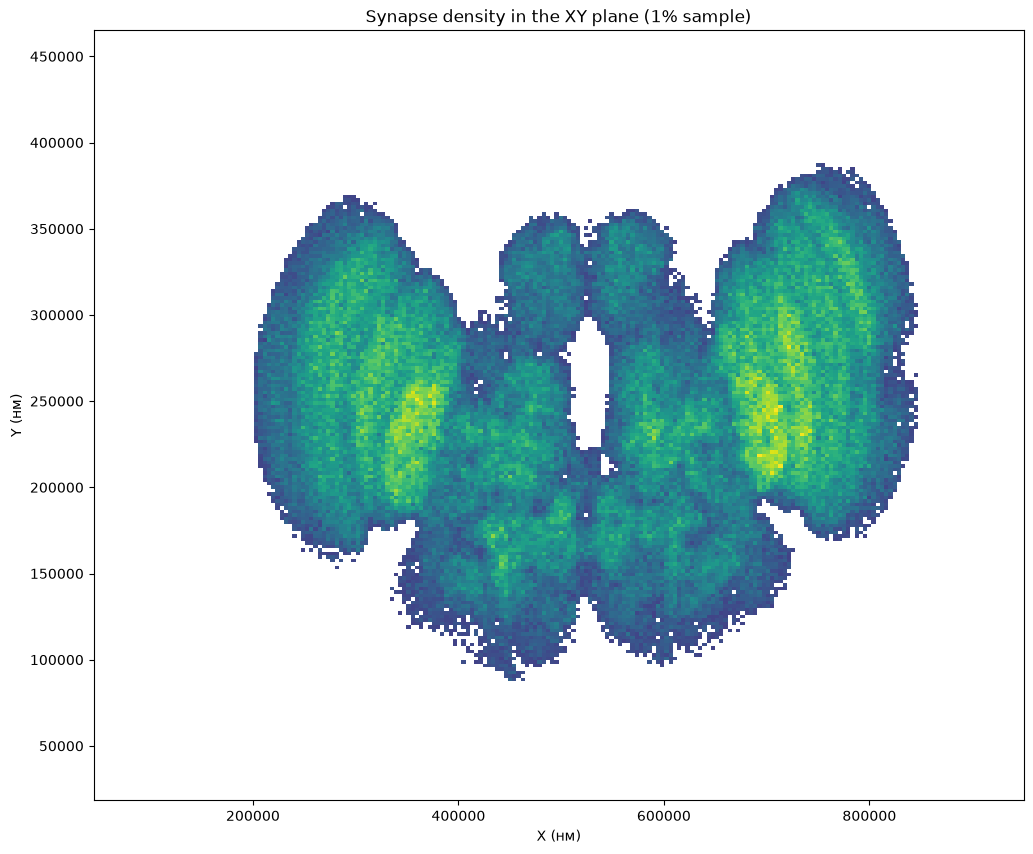

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Data random sample 1% (~ 1.3 million of synapses) for speed
sample_df = df.sample(frac=0.01, random_state=42)

plt.figure(figsize=(12, 10))
# Building 2-D gistogramm densities as a function of coordinates pre_x и pre_y
sns.histplot(
    data=sample_df, 
    x='pre_x', 
    y='pre_y', 
    bins=200, 
    cmap='viridis', 
    pthresh=0.05
)
plt.title('Synapse density in the XY plane (1% sample)')
plt.xlabel('X (нм)')
plt.ylabel('Y (нм)')
plt.show()

In [17]:
import plotly.express as px

# Take 0.1% of data - prevention of freezing and lags
sample_3d = df.sample(frac=0.001, random_state=42)

fig = px.scatter_3d(
    sample_3d,
    x='pre_x', 
    y='pre_y', 
    z='pre_z',
    opacity=0.1, # Make dots transparent for seeing Size
    title='3D-Cloud of Synapses (0.1% sample)',
    width=1000, height=800
)
fig.show(renderer="browser")

In [18]:
# Save graph as file .html
fig.write_html("3d_brain.html")
print("Graph is saved as 3d_brain.html")

Graph is saved as 3d_brain.html


In [19]:
import nbformat
print("Version nbformat:", nbformat.__version__)

Version nbformat: 5.11.1


In [20]:
import plotly.express as px

# Take 0.1% of data for browser lag preventions
sample_3d = df.sample(frac=0.001, random_state=42)

fig = px.scatter_3d(
    sample_3d,
    x='pre_x', 
    y='pre_y', 
    z='pre_z',
    opacity=0.1, 
    title='3D-Cloud of Synapses (0.1% Sample)',
    width=1000, height=800
)
fig.show()